In [1]:
# Integración con el entorno de Jupyter/Colab
from IPython.display import HTML, display

def set_css():
  display(HTML('''
  <style>
    pre {
        white-space: pre-wrap;
    }
  </style>
  '''))

# Computación científica y análisis de datos
import numpy as np

# Visualización de datos
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import plotly.graph_objects as go

# Librerías estándar de Python
import json

#Diferenciación automática

In [2]:
def suma(a, da, b, db):
  """
  Suma de dos variables: f(a, b) = a + b
  Derivada: df = da + db
  """
  return a+b, da+db

def producto(a, da, b, db):
  """
  Producto de dos variables: f(a, b) = a * b
  Derivada: df = a * db + da * b (regla del producto)
  """
  return a*b, a*db + da*b

def division(a, da, b, db):
  """
  División de dos variables: f(a, b) = a / b
  Derivada: df = (b * da - a * db) / b^2 (regla del cociente)
  """
  return a/b, (b*da - a*db)/(b**2)

def seno(a, da):
  """
  Función seno: f(a) = sen(a)
  Derivada: df = cos(a) * da (regla de la cadena)
  """
  return np.sin(a), da*np.cos(a)

def coseno(a, da):
  """
  Función coseno: f(a) = cos(a)
  Derivada: df = -sin(a) * da (regla de la cadena)
  """
  return np.cos(a), -da*np.sin(a)

def tanhiperbolica(a, da):
  """
  Tangente hiperbólica: f(a) = tanh(a)
  Derivada: df = (1 - tanh^2(a)) * da (regla de la cadena)
  """
  valor = np.tanh(a)
  return valor, (1 - valor**2)*da

In [3]:
# Definimos el punto de evaluación
x = 2.2

# Calculamos la función f(x) = x * x y su derivada usando diferenciación automática.
# Pasamos 'x' con semilla de derivada 1, y el otro factor 'x' con semilla de derivada 1.
valor, derivada = producto(x, 1, x, 1)

print(f"f({x}) = {valor}")
print(f"f'({x}) = {derivada}")

f(2.2) = 4.840000000000001
f'(2.2) = 4.4


In [4]:
# Punto de evaluación para la función f(x) = (2x + 1)^2
x = 2.2
dx = 1.0  # Semilla para la derivada con respecto a x

# Paso 1: u = 2 * x
u, du = producto(2.0, 0.0, x, dx)

# Paso 2: c = u + 1
c, dc = suma(u, du, 1.0, 0.0)

# Paso 3: f = c * c = (2x + 1)^2
val_f2, der_f2 = producto(c, dc, c, dc)

print(f"f({x}) = {val_f2}")
print(f"f'({x}) = {der_f2}")

f(2.2) = 29.160000000000004
f'(2.2) = 21.6


Computemos la deriva de:

$f(x) = x^2$


$f(x) = (2x+1)^2$

In [5]:
# Punto de evaluación
x = 2.2
dx = 1.0  # Semilla para la derivada con respecto a x

# ANSI escape codes: \033[1m activa negrita, \033[0m la desactiva
print("\033[1mEjemplo 1: f(x) = x^2\033[0m")
# f(x) = x * x
val_f1, der_f1 = producto(x, dx, x, dx)

print(f"f({x}) = {val_f1}")
print(f"f'({x}) = {der_f1}")

#######################################

print("\033[1mEjemplo 2: f(x) = (2x + 1)^2\033[0m")
# Primero calculamos u = 2 * x
u, du = producto(2.0, 0.0, x, dx)
# Luego c = u + 1
c, dc = suma(u, du, 1.0, 0.0)
# Finalmente f = c * c
val_f2, der_f2 = producto(c, dc, c, dc)

print(f"f({x}) = {val_f2}")
print(f"f'({x}) = {der_f2}")

Ejemplo 1: f(x) = x^2
f(2.2) = 4.840000000000001
f'(2.2) = 4.4
Ejemplo 2: f(x) = (2x + 1)^2
f(2.2) = 29.160000000000004
f'(2.2) = 21.6


$
f(x)=\sin\!\bigl(\cos(x^2)\bigr),
$

$
u=x^2,\qquad u'=2x,
$

$
v=\cos(u),\qquad v'=-\sin(u)\,u',
$


$
f=\sin(v),\qquad f'=\cos(v)\,v'.
$


$
f'(x)=-2x\,\sin(x^2)\,\cos\!\bigl(\cos(x^2)\bigr).
$

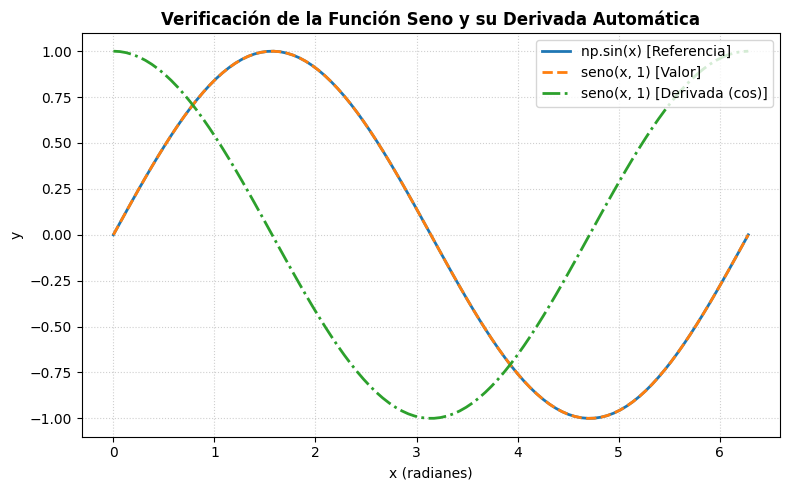

In [6]:
x = np.linspace(0, 2*np.pi, 100)
val_sin, der_sin = seno(x, 1)

# Crear la figura y el objeto de los ejes (enfoque orientado a objetos)
fig, ax = plt.subplots(figsize=(8, 5))

# Graficar los resultados utilizando el objeto ax
ax.plot(x, np.sin(x), label="np.sin(x) [Referencia]", linestyle="-", linewidth=2)
ax.plot(x, val_sin, label="seno(x, 1) [Valor]", linestyle="--", linewidth=2)
ax.plot(x, der_sin, label="seno(x, 1) [Derivada (cos)]", linestyle="-.", linewidth=2)

# Personalización del gráfico
ax.set_title("Verificación de la Función Seno y su Derivada Automática", fontsize=12, fontweight='bold')
ax.set_xlabel("x (radianes)", fontsize=10)
ax.set_ylabel("y", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

Evaluamos la precisión del método de diferenciación automática frente a una función altamente no lineal:

$$f(x) = \sin(\cos(x^2))$$

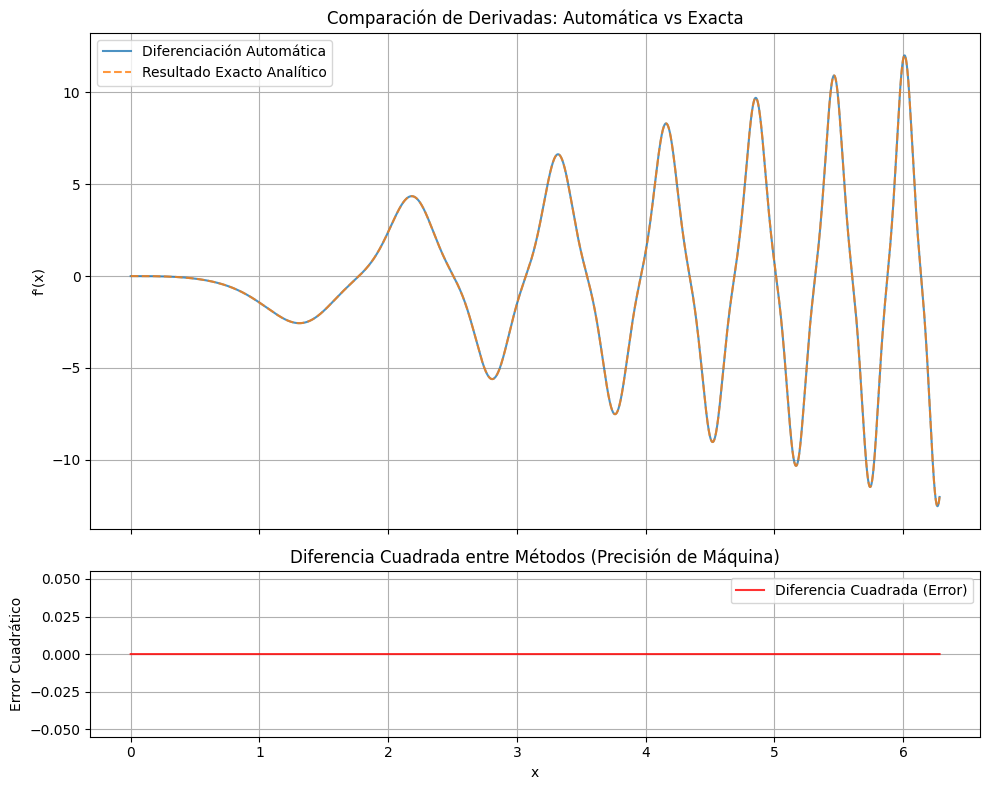

In [7]:
x = np.linspace(0, 2*np.pi, 10000)

# Diferenciación automática
u, du = producto(x, 1, x, 1)
c, dc = coseno(u, du)
r, dr = seno(c, dc)

# Resultado analítico exacto
# f'(x) = -2 * x * sin(x^2) * cos(cos(x^2))
derivada_exacta = -2 * x * np.sin(x**2) * np.cos(np.cos(x**2))

# Calcular la diferencia al cuadrado (error cuadrático)
dfsqr = (dr - derivada_exacta)**2

# Crear los subplots estableciendo una relación de aspecto que haga el segundo subplot más fino (ratio 3:1)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

# Subplot 1: Comparación directa
ax1.plot(x, dr, label=f"Diferenciación Automática", linestyle="-", alpha=0.8)
ax1.plot(x, derivada_exacta, label=f"Resultado Exacto Analítico", linestyle="--", alpha=0.8)
ax1.set_ylabel(f"f'(x)")
ax1.set_title(f"Comparación de Derivadas: Automática vs Exacta")
ax1.legend()
ax1.grid(True)

# Subplot 2: Diferencia al cuadrado (más fino)
ax2.plot(x, dfsqr, label=f"Diferencia Cuadrada (Error)", color="red", alpha=0.8)
ax2.set_xlabel(f"x")
ax2.set_ylabel(f"Error Cuadrático")
ax2.set_title(f"Diferencia Cuadrada entre Métodos (Precisión de Máquina)")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

$$
\begin{align}
f(x)
&=
\sin(cos(x^2))
+
\tan(\sin(x^3))
\\
&=
\sin(cos(x^2))
+
\frac{
\sin(\sin(x^3))
}{
\cos(\sin(x^3))
}
\end{align}
$$

In [8]:
# Semilla y punto de evaluación
dx = 1
x = 1

# Primer término: s = sin(cos(x^2))
u, du = producto(x, dx, x, dx)  # x^2
c, dc = coseno(u, du)           # cos(x^2)
s, ds = seno(c, dc)             # sin(cos(x^2))

# Segundo término: sol = tan(sin(x^3)) = sin(sin(x^3)) / cos(sin(x^3))
p, dp = producto(x, dx, x, dx)  # x^2
k, dk = producto(p, dp, x, dx)  # x^3
q, dq = seno(k, dk)             # sin(x^3)

y1, dy1 = seno(q, dq)           # sin(sin(x^3))
y2, dy2 = coseno(q, dq)         # cos(sin(x^3))

sol, dsol = division(y1, dy1, y2, dy2) # tan(sin(x^3))

# Suma final de ambos términos
resultado, derivada = suma(s, ds, sol, dsol)

print(f"Resultado de la función f({x}) = {resultado}")
print(f"Derivada f'({x}) = {derivada}")

Resultado de la función f(1) = 1.6333348617085015
Derivada f'(1) = 2.2071119573816356


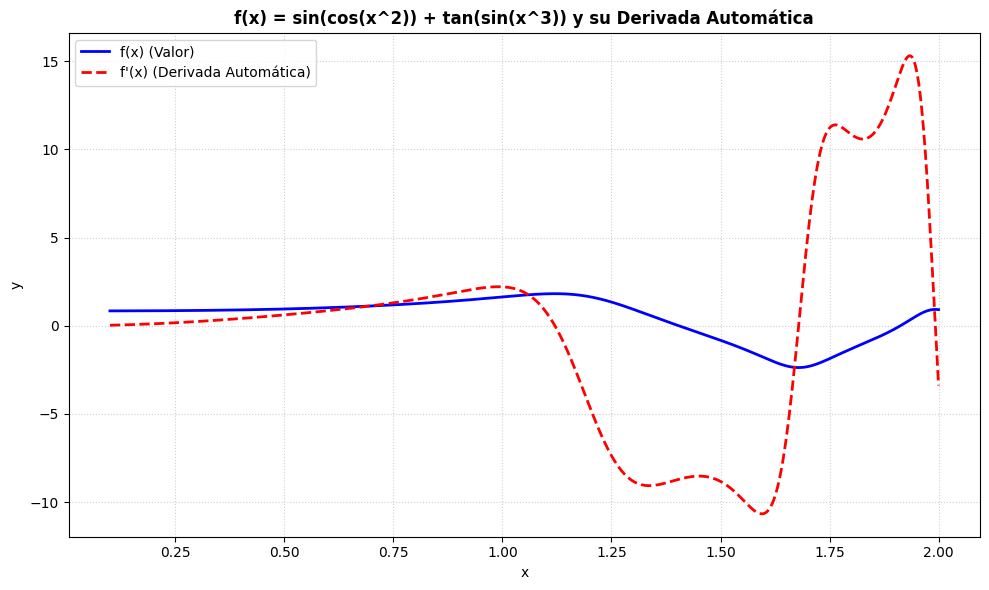

In [9]:
# Definir un rango de evaluación
x_vals = np.linspace(0.1, 2.0, 500)
dx_vals = np.ones_like(x_vals)

# Primer término: s = sin(cos(x^2))
u, du = producto(x_vals, dx_vals, x_vals, dx_vals)  # x^2
c, dc = coseno(u, du)           # cos(x^2)
s, ds = seno(c, dc)             # sin(cos(x^2))

# Segundo término: sol = tan(sin(x^3)) = sin(sin(x^3)) / cos(sin(x^3))
p, dp = producto(x_vals, dx_vals, x_vals, dx_vals)  # x^2
k, dk = producto(p, dp, x_vals, dx_vals)  # x^3
q, dq = seno(k, dk)             # sin(x^3)

y1, dy1 = seno(q, dq)           # sin(sin(x^3))
y2, dy2 = coseno(q, dq)         # cos(sin(x^3))

sol, dsol = division(y1, dy1, y2, dy2) # tan(sin(x^3))

# Suma final de ambos términos
resultado, derivada = suma(s, ds, sol, dsol)

# Graficar los resultados
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_vals, resultado, label="f(x) (Valor)", color="blue", linewidth=2)
ax.plot(x_vals, derivada, label="f'(x) (Derivada Automática)", color="red", linestyle="--", linewidth=2)

ax.set_title("f(x) = sin(cos(x^2)) + tan(sin(x^3)) y su Derivada Automática", fontsize=12, fontweight='bold')
ax.set_xlabel("x", fontsize=10)
ax.set_ylabel("y", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()

Supongamos que tenemos dos conectadas y queremos computar una diferenciacion automática cuyas funciones de activación son tanh:

\begin{equation}
\frac{da_2}{dx}
=
\frac{da_2}{dz_2}
\frac{dz_2}{da_1}
\frac{da_1}{dz_1}
\frac{dz_1}{dx}
=
(1-\tanh Z_2^2)\,w_2\,(1-\tanh Z_1^2)\,w_1.
\end{equation}



In [10]:
# Parámetros de entrada y pesos de la red
x = 0.8
w = 0.1
b = 0.1

# Primera capa
z = w*x + b
a1 = np.tanh(z)

# Segunda capa
z2 = w*a1 + b
a2 = np.tanh(z2)

# Cálculo analítico de la derivada de a2 respecto a x usando la regla de la cadena
derivada = (1-(np.tanh(z2))**2) * (1-(np.tanh(z))**2) * w**2

print(f"Activación final a2: {a2}")
print(f"Derivada analítica da2/dx: {derivada}")

Activación final a2: 0.11726608605144122
Derivada analítica da2/dx: 0.009549719627467191


Activación final a2 (modularizada): 0.11726608605144122
Derivada da2/dx (modularizada): 0.009549719627467191


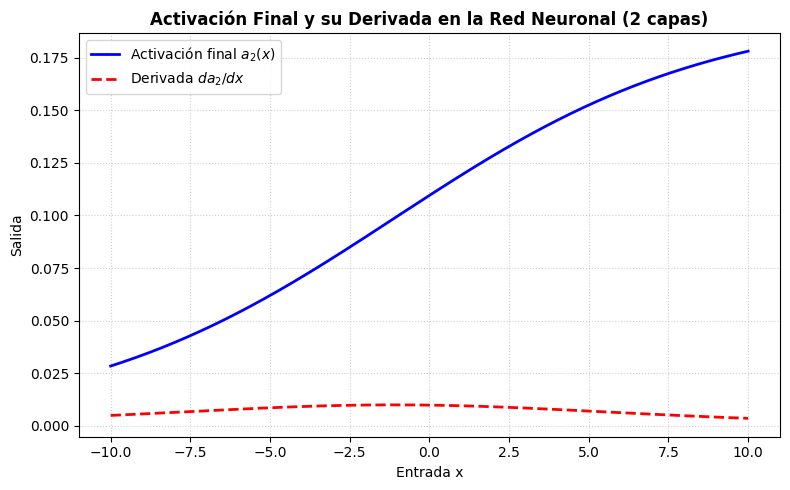

In [11]:
def dneurona(x, dx, w, b):
  """
  Calcula la activación y la derivada para una neurona individual con activación tanh.
  """
  # Operaciones de la neurona utilizando diferenciación automática
  t1, dt1 = producto(w, 0, x, dx)
  z, dz = suma(t1, dt1, b, 0)
  a1, da1 = tanhiperbolica(z, dz)
  return a1, da1

# Evaluación de la primera capa
a1, da1 = dneurona(x, 1, w, b)

# Evaluación de la segunda capa pasándole la salida de la primera
a2, da2 = dneurona(a1, da1, w, b)

print(f"Activación final a2 (modularizada): {a2}")
print(f"Derivada da2/dx (modularizada): {da2}")

# Evaluamos la red neuronal sobre un rango de valores para graficar los resultados
x_vals = np.linspace(-10.0, 10.0, 400)
dx_vals = np.ones_like(x_vals)

# Evaluamos la primera capa usando la función dneurona
a1_vals, da1_vals = dneurona(x_vals, dx_vals, w, b)

# Evaluamos la segunda capa pasándole la salida y derivada de la primera
a2_vals, da2_vals = dneurona(a1_vals, da1_vals, w, b)

# Crear la gráfica
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_vals, a2_vals, label="Activación final $a_2(x)$", color="blue", linewidth=2)
ax.plot(x_vals, da2_vals, label="Derivada $da_2/dx$", color="red", linestyle="--", linewidth=2)

ax.set_title("Activación Final y su Derivada en la Red Neuronal (2 capas)", fontsize=12, fontweight='bold')
ax.set_xlabel("Entrada x", fontsize=10)
ax.set_ylabel("Salida", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

### Modularización de una Neurona con Diferenciación Automática

Para facilitar la escalabilidad de la red neuronal, podemos encapsular las operaciones de una neurona individual dentro de una funcián modularizada llamada `dneurona`.

Esta función realiza de forma automática tanto el paso hacia adelante (**forward pass**) para calcular las activaciones, como el paso hacia atrás (**backward pass**) utilizando las reglas de derivación definidas previamente:

1. **Cólculo del valor de preactivación ($z$):** Combina de forma lineal la entrada $x$ (con su semilla de derivada $dx$) y el peso $w$, sumando el sesgo $b$.
2. **Aplicación de la función de activación:** Evalúa el valor resultante mediante la función tangente hiperbólica y propaga la derivada final utilizando la regla de la cadena.

In [12]:
# Primera capa: t1 = w * x, seguido de z = t1 + b
t1, dt1 = producto(w, 0, x, 1)
z, dz = suma(t1, dt1, b, 0)
a1, da1 = tanhiperbolica(z, dz)

# Segunda capa: t2 = w * a1, seguido de z2 = t2 + b
t2, dt2 = producto(w, 0, a1, da1)
z2, dz2 = suma(t2, dt2, b, 0)
a2, da2 = tanhiperbolica(z2, dz2)

print(f"Activación final a2: {a2}")
print(f"Derivada da2/dx: {da2}")

Activación final a2: 0.11726608605144122
Derivada da2/dx: 0.009549719627467191


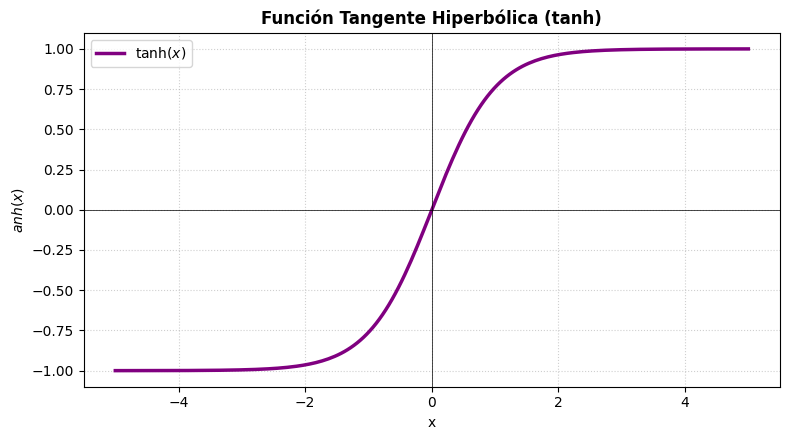

In [13]:
# Graficar la función tangente hiperbólica
x_tanh = np.linspace(-5.0, 5.0, 200)
y_tanh = np.tanh(x_tanh)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x_tanh, y_tanh, label=r'$\tanh(x)$', color='purple', linewidth=2.5)

# Personalización de la gráfica
ax.set_title("Función Tangente Hiperbólica (tanh)", fontsize=12, fontweight='bold')
ax.set_xlabel("x", fontsize=10)
ax.set_ylabel("$\tanh(x)$", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)
ax.axhline(0, color='black',linewidth=0.5)
ax.axvline(0, color='black',linewidth=0.5)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

### Difusión de calor en una placa cuadrada

Considere una placa homogénea de lado $L$, sin fuentes internas
de calor y con temperatura uniforme a través de su espesor.
Su difusividad térmica es constante:

$$
\alpha=\frac{k}{\rho c_p},
$$

donde $k$ es la conductividad térmica, $\rho$ la densidad y
$c_p$ el calor específico.

Determine la temperatura $T(x,y,t)$ en el dominio
$(x,y)\in(0,L)^2$, para $t>0$, mediante la ecuación de calor:

$$
\frac{\partial T}{\partial t}
=
\alpha\left(
\frac{\partial^2T}{\partial x^2}
+
\frac{\partial^2T}{\partial y^2}
\right).
$$

Los cuatro bordes permanecen a temperatura constante $T_b$:

$$
T(0,y,t)=T(L,y,t)=T(x,0,t)=T(x,L,t)=T_b.
$$

La temperatura inicial es:

$$
T(x,y,0)=T_b+\Delta T
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right),
$$

donde $\Delta T>0$ es la diferencia inicial entre la temperatura
del centro y la de los bordes.

Aproximar $T(x,y,t)$ mediante una PINN,
minimizando el residual de la ecuación y los errores en las
condiciones iniciales y de frontera. Comparar el resultado
con la solución analítica:

$$
T(x,y,t)=T_b+\Delta T
e^{-2\alpha\pi^2t/L^2}
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right).
$$

In [14]:
Lx = 1.0 # Longitud en x [m]
Ly = 1.0 # Longitud en y [m]
Tb = 300 + 273.15 # Temperatura fija de los bordes [K]
delta_T = 100.0 # Diferencia inicial centro-bordes [K]

alpha = 1e-4  # Difusividad térmica [m²/s]
params = {'Lx': Lx, 'Ly': Ly, 'Tb': Tb, "delta":delta_T ,'alpha': alpha}

# Imprimir el diccionario formateado como JSON
print(json.dumps(params, indent=4))

def T(x, y, t, **params):
  """
  Calcula la solución analítica de la ecuación de calor en 2D
  para una placa homogénea en una posición (x, y) y tiempo t en Kelvin.
  """
  # Extraer los parámetros térmicos y geométricos del diccionario
  Lx = params['Lx']
  Ly = params['Ly']
  Tb = params['Tb']
  alpha = params['alpha']

  # Componente espacial de la solución (distribución senoidal)
  u = np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly)

  # Combinación de la temperatura de borde, el decaimiento temporal exponencial y el patrón espacial
  return Tb + delta_T * np.exp(-2*alpha*np.pi**2*t/(Lx*Ly))*u

{
    "Lx": 1.0,
    "Ly": 1.0,
    "Tb": 573.15,
    "delta": 100.0,
    "alpha": 0.0001
}


In [15]:
nx, ny = 30, 30
tiempo_final = 500.0

x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Límite de estabilidad para diferencias finitas con Euler explícito
dt_max = 1 / (
    2 * params["alpha"] * (1 / dx**2 + 1 / dy**2)
)
# Margen de seguridad del 10 %
nt = int(np.ceil(tiempo_final / (0.9 * dt_max))) + 1

t = np.linspace(0, tiempo_final, nt)
dt = t[1] - t[0]
X, Y = np.meshgrid(x, y, indexing="ij")
nx, ny, nt = len(x), len(y), len(t)
Temperatura = np.zeros((nt,nx, ny))

# Redefinimos los arreglos espaciales para evitar conflictos con variables previas
x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)

# Establecemos la condición inicial para t = 0
# T(x, y, 0) = Tb + delta_T * sin(pi * x / Lx) * sin(pi * y / Ly)
for i in range(nx):
    for j in range(ny):
        Temperatura[0, i, j] = T(x[i], y[j], 0, **params)

print(f"Condiciones iniciales establecidas. Temperatura máxima inicial: {Temperatura[0].max():.2f} K")

Condiciones iniciales establecidas. Temperatura máxima inicial: 672.86 K


In [16]:
# Implementación del método de diferencias finitas en el tiempo (Euler explícito)
for n in range(0, nt - 1):
    # Copiamos la temperatura del paso anterior para aplicar las condiciones de frontera
    Temperatura[n + 1, :, :] = params['Tb']

    # Actualizamos los nodos internos de la placa
    for i in range(1, nx - 1):
        for j in range(1, ny - 1):
            d2T_dx2 = (Temperatura[n, i + 1, j] - 2 * Temperatura[n, i, j] + Temperatura[n, i - 1, j]) / (dx**2)
            d2T_dy2 = (Temperatura[n, i, j + 1] - 2 * Temperatura[n, i, j] + Temperatura[n, i, j - 1]) / (dy**2)

            Temperatura[n + 1, i, j] = Temperatura[n, i, j] + params['alpha'] * dt * (d2T_dx2 + d2T_dy2)

print(f"Simulación completada para {nt} pasos de tiempo de tamaño dt = {dt:.4f} s.")

Simulación completada para 188 pasos de tiempo de tamaño dt = 2.6738 s.


In [17]:
def graficar_planos(
    Temperatura, Lx, Ly,
    tiempos=None,
    n_planos=5,
    opacidad=0.5
):
    nt, nx, ny = Temperatura.shape

    x = np.linspace(0, Lx, nx)
    y = np.linspace(0, Ly, ny)
    X, Y = np.meshgrid(x, y, indexing="ij")

    titulo_t = "Tiempo [s]" if tiempos is not None else "Índice de tiempo"
    tiempos = np.arange(nt) if tiempos is None else np.asarray(tiempos)

    # Seleccionar pocos tiempos, incluyendo el primero y el último.
    indices = np.unique(
        np.linspace(0, nt - 1, min(n_planos, nt), dtype=int)
    )

    # Escala de colores común.
    Tmin = float(np.nanmin(Temperatura))
    Tmax = float(np.nanmax(Temperatura))

    if Tmin == Tmax:
        Tmin -= 0.5
        Tmax += 0.5

    fig = go.Figure()

    # Invertimos los índices para dibujar de atrás hacia adelante (back-to-front)
    # y así solucionar el problema de solapamiento con la opacidad.
    for j, k in enumerate(indices[::-1]):
        fig.add_trace(go.Surface(
            x=np.full(X.shape, tiempos[k], dtype=float),
            y=X,
            z=Y,
            surfacecolor=Temperatura[k],
            colorscale="turbo",
            cmin=Tmin,
            cmax=Tmax,
            opacity=opacidad,
            showscale=(j == 0),
            colorbar=dict(title="Temperatura [K]"),
            lighting=dict(ambient=1, diffuse=0, specular=0),
            name=f"Temperatura[{k}]",
            hovertemplate=(
                "Tiempo / índice = %{x:.3f}<br>"
                "x = %{y:.3f} m<br>"
                "y = %{z:.3f} m<br>"
                "T = %{surfacecolor:.2f} K"
                "<extra>%{fullData.name}</extra>"
            )
        ))

    fig.update_layout(
        height=650,
        scene=dict(
            xaxis_title=titulo_t,
            yaxis_title="x [m]",
            zaxis_title="y [m]",
            aspectmode="manual",
            aspectratio=dict(x=1.6, y=1, z=Ly / Lx),
            camera=dict(eye=dict(x=-1.7, y=-1.7, z=0.8))
        ),
        margin=dict(l=0, r=0, b=0, t=30)
    )

    return fig

graficar_planos(
    Temperatura, Lx, Ly,
    n_planos=10,
    opacidad=0.9
)

In [18]:
fig = graficar_planos(
    Temperatura, Lx, Ly,
    n_planos=10,
    opacidad=1
)
fig.show()

In [19]:
Temperatura.shape

(188, 30, 30)

In [20]:
len(Temperatura)

188

In [21]:
n_frames = len(Temperatura)

# Definir cuadros por segundo (FPS) deseados
fps = 30
intervalo_ms = int(1000 / fps)

fig, ax = plt.subplots(figsize=(6, 5))

imagen = ax.imshow(
    Temperatura[0],
    cmap="turbo",
    vmin=np.nanmin(Temperatura[:n_frames]),
    vmax=np.nanmax(Temperatura[:n_frames])
)

fig.colorbar(imagen, ax=ax, label="Temperatura [K]")
titulo = ax.set_title("Temperatura[0]")

def actualizar(i):
    imagen.set_data(Temperatura[i])
    titulo.set_text(f"Temperatura[{i}]")
    return imagen, titulo

animacion = FuncAnimation(
    fig,
    actualizar,
    frames=n_frames,
    interval=intervalo_ms,
    repeat=True
)

plt.close(fig)
display(HTML(animacion.to_jshtml()))